In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import seaborn as sns
from matplotlib import pyplot as plt

sns.set_theme(
    context="talk",
    style="whitegrid",
    palette="deep",
    color_codes=True,
    rc={"figure.dpi": 150},
)

In [2]:
data = yf.Ticker("AAPL").history(start="1996-01-01", end="2026-10-27")
data.index = data.index.tz_localize(None)
data = data.reset_index()

data["Simple_Return"] = data["Close"].pct_change()
data["Log_Return"] = np.log(data["Close"] / data["Close"].shift(1))
data[["Date", "Close", "Simple_Return", "Log_Return"]].head()

,Date,Close,Simple_Return,Log_Return
0,1996-01-02,0.240211,NaN,NaN
1,1996-01-03,0.240211,0.000000,0.000000
2,1996-01-04,0.236006,-0.017509,-0.017664
3,1996-01-05,0.256102,0.085150,0.081719
4,1996-01-08,0.258905,0.010948,0.010889


In [3]:
df_cpi = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL")
df_cpi.reset_index(drop=True).head()

,observation_date,CPIAUCSL
0,1947-01-01,21.48
1,1947-02-01,21.62
2,1947-03-01,22.00
3,1947-04-01,22.00
4,1947-05-01,21.95


In [4]:
monthly = data.set_index("Date")["Close"].resample("MS").last().to_frame("Close")

cpi = df_cpi.rename(columns={"observation_date": "date", "CPIAUCSL": "cpi"})
cpi["date"] = pd.to_datetime(cpi["date"])
cpi = cpi.set_index("date")

merged = monthly.join(cpi, how="inner").reset_index()
merged.head()

,Date,Close,cpi
0,1996-01-01,0.206564,154.7
1,1996-02-01,0.205629,155.0
2,1996-03-01,0.183664,155.5
3,1996-04-01,0.182262,156.1
4,1996-05-01,0.195347,156.4


In [5]:
merged["simple_return"] = merged["Close"].pct_change()
merged["log_return"] = np.log(merged["Close"] / merged["Close"].shift(1))
merged["inflation"] = merged["cpi"].pct_change()
merged["real_return"] = (1 + merged["simple_return"]) / (1 + merged["inflation"]) - 1
merged.head()

,Date,Close,cpi,simple_return,log_return,inflation,real_return
0,1996-01-01,0.206564,154.7,NaN,NaN,NaN,NaN
1,1996-02-01,0.205629,155.0,-0.004525,-0.004535,0.001939,-0.006451
2,1996-03-01,0.183664,155.5,-0.106820,-0.112967,0.003226,-0.109691
3,1996-04-01,0.182262,156.1,-0.007633,-0.007662,0.003859,-0.011447
4,1996-05-01,0.195347,156.4,0.071794,0.069334,0.001922,0.069738


In [6]:
px = data.set_index("Date")["Close"]
log_ret = data.set_index("Date")["Log_Return"]  # daily log return

freq_returns = {
    f: px.resample(f).last().pct_change().dropna() for f in ["W", "MS", "QS", "YS"]
}

# Additivity check: daily log return jog = monthly log return
monthly_log = log_ret.resample("MS").sum()
check = np.log(px.resample("MS").last()).diff()
print(
    "Log return additivity ok:",
    np.allclose(monthly_log.iloc[1:], check.iloc[1:], atol=1e-6),
)

summary = pd.DataFrame(
    {
        "mean": {f: r.mean() for f, r in freq_returns.items()},
        "std": {f: r.std() for f, r in freq_returns.items()},
        "count": {f: len(r) for f, r in freq_returns.items()},
    }
)
summary

Log return additivity ok: True


,mean,std,count
W,0.005996,0.054335,1608
MS,0.027134,0.114808,369
QS,0.088247,0.233398,123
YS,0.463430,0.704180,30


In [7]:
# Monthly RV: sqrt(sum r^2) * sqrt(12)
rv_monthly = log_ret.pow(2).resample("MS").sum().pow(0.5) * np.sqrt(12)
rv_monthly = rv_monthly.iloc[:-1]  # October 2026 partial month bad

# Rolling 21-day RV: std * sqrt(252)
rv_21d = log_ret.rolling(21).std() * np.sqrt(252)

rv_monthly.tail()

Date
2026-05-01    0.196447
2026-06-01    0.349196
2026-07-01    0.395544
2026-08-01    0.183942
2026-09-01    0.235253
Freq: MS, Name: Log_Return, dtype: float64

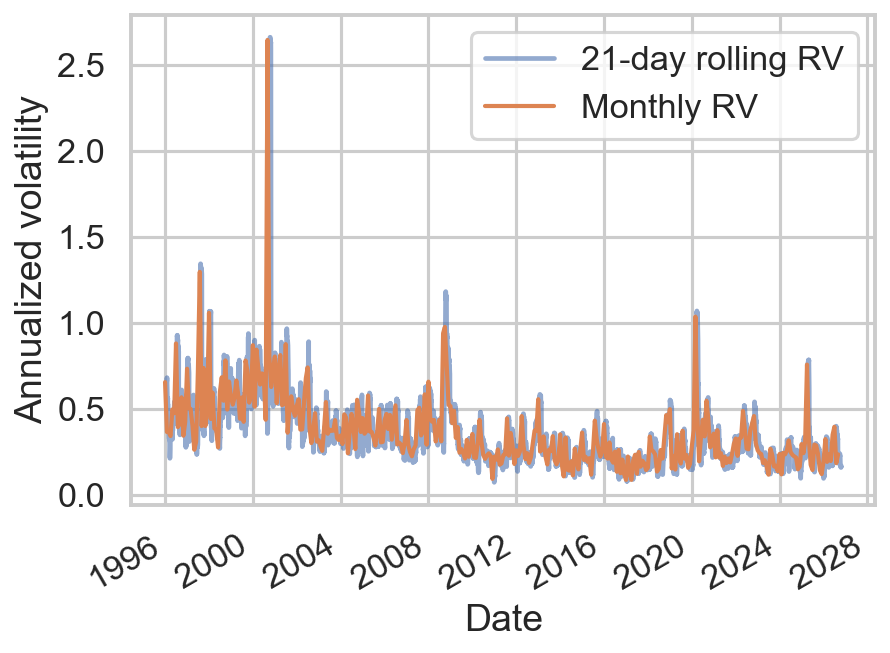

In [8]:
fig, ax = plt.subplots()
rv_21d.plot(ax=ax, label="21-day rolling RV", alpha=0.6)
rv_monthly.plot(ax=ax, label="Monthly RV", linewidth=2)
ax.set_ylabel("Annualized volatility")
ax.legend()
plt.show()